# Lab 1 – podstawowa analiza obrazu

W tym ćwiczeniu samodzielnie przeprowadzisz podstawową analizę obrazu cyfrowego z wykorzystaniem biblioteki `scikit-image`.

Twoim celem jest przejście przez cały prosty proces analizy:

**wczytanie obrazu → sprawdzenie jego właściwości → analiza kanałów → skala szarości → histogram → normalizacja → wyrównanie histogramu**


## 1. Wybierz obraz

Wybierz jeden obraz z wbudowanej bazy:

```python
skimage.data
```

Możesz wykorzystać np.:

```python
data.camera()
data.coins()
data.chelsea()
data.coffee()
data.horse()
data.moon()
data.rocket()
```

Nie wybieraj obrazu `astronaut`, ponieważ był już analizowany podczas zajęć.

Wyświetl wybrany obraz.


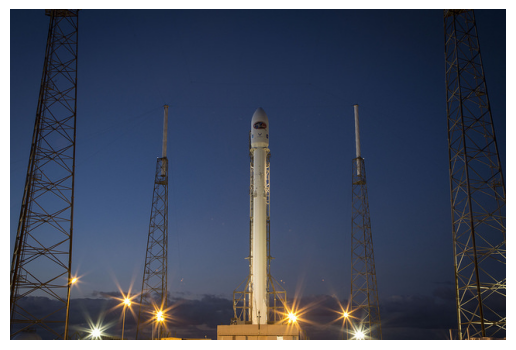

In [10]:
from skimage import data, color, exposure, img_as_float
import numpy as np
import matplotlib.pyplot as plt

# Wczytaj wybrany obraz
img = data.rocket()

# Wyświetl obraz
plt.imshow(img)
plt.axis("off")
plt.show()

## 2. Sprawdź podstawowe informacje o obrazie

Sprawdź:

```python
img.shape
img.dtype
img.min()
img.max()
```

Zwróć uwagę na:

- wymiary obrazu,
- liczbę kanałów,
- typ danych,
- minimalną i maksymalną wartość pikseli.

### Zastanów się

Co informacje zwracane przez `shape` mówią o obrazie?  
Czy wartości pikseli są zapisane w zakresie `0–255`, czy `0–1`?


In [11]:
print("Wymiary obrazu:", img.shape)
print("Typ danych:", img.dtype)
print("Minimalna wartość:", img.min())
print("Maksymalna wartość:", img.max())


Wymiary obrazu: (427, 640, 3)
Typ danych: uint8
Minimalna wartość: 0
Maksymalna wartość: 255


## 3. Określ rodzaj obrazu

Na podstawie wymiarów określ, czy obraz jest:

- obrazem w skali szarości,
- obrazem RGB,
- obrazem RGBA.

Przykładowo:

```text
(wysokość, szerokość)
```

oznacza zazwyczaj obraz w skali szarości,

natomiast:

```text
(wysokość, szerokość, 3)
```

oznacza obraz RGB.


In [14]:
if len(img.shape) == 3:
    print("Obraz jest w formacie RGB.")
elif len(img.shape) == 4:
    print("Obraz jest w formacie RGBA.")
elif len(img.shape) == 2:
    print("Obraz jest w formacie skali szarości.")

Obraz jest w formacie RGB.


## 4. Przeanalizuj kanały obrazu

Jeżeli wybrany obraz jest obrazem RGB, wydziel jego trzy kanały:

- R – czerwony,
- G – zielony,
- B – niebieski.

Wyświetl obok siebie:

**obraz RGB | kanał R | kanał G | kanał B**

Kanały możesz wyświetlić w skali szarości, ponieważ wtedy jasność piksela pokazuje intensywność danego kanału.

### Zastanów się

W których fragmentach obrazu poszczególne kanały są najjaśniejsze?  
Czy da się powiązać to z kolorami widocznymi na obrazie oryginalnym?

Jeśli obraz jest już w skali szarości, pomiń ten etap.


[[[ 17   0   0]
  [ 17   0   0]
  [ 17   0   0]
  ...
  [  8   0   0]
  [  8   0   0]
  [  7   0   0]]

 [[ 17   0   0]
  [ 17   0   0]
  [ 17   0   0]
  ...
  [  8   0   0]
  [  8   0   0]
  [  8   0   0]]

 [[ 18   0   0]
  [ 18   0   0]
  [ 18   0   0]
  ...
  [  8   0   0]
  [  8   0   0]
  [  8   0   0]]

 ...

 [[ 27   0   0]
  [ 29   0   0]
  [ 20   0   0]
  ...
  [136   0   0]
  [186   0   0]
  [173   0   0]]

 [[ 26   0   0]
  [ 29   0   0]
  [ 30   0   0]
  ...
  [103   0   0]
  [ 97   0   0]
  [ 76   0   0]]

 [[ 26   0   0]
  [ 29   0   0]
  [ 40   0   0]
  ...
  [ 82   0   0]
  [ 79   0   0]
  [ 83   0   0]]]
[[[  0  33   0]
  [  0  33   0]
  [  0  33   0]
  ...
  [  0  19   0]
  [  0  19   0]
  [  0  18   0]]

 [[  0  33   0]
  [  0  33   0]
  [  0  33   0]
  ...
  [  0  19   0]
  [  0  19   0]
  [  0  19   0]]

 [[  0  34   0]
  [  0  34   0]
  [  0  34   0]
  ...
  [  0  19   0]
  [  0  19   0]
  [  0  19   0]]

 ...

 [[  0  28   0]
  [  0  29   0]
  [  0  24   0]
  ..

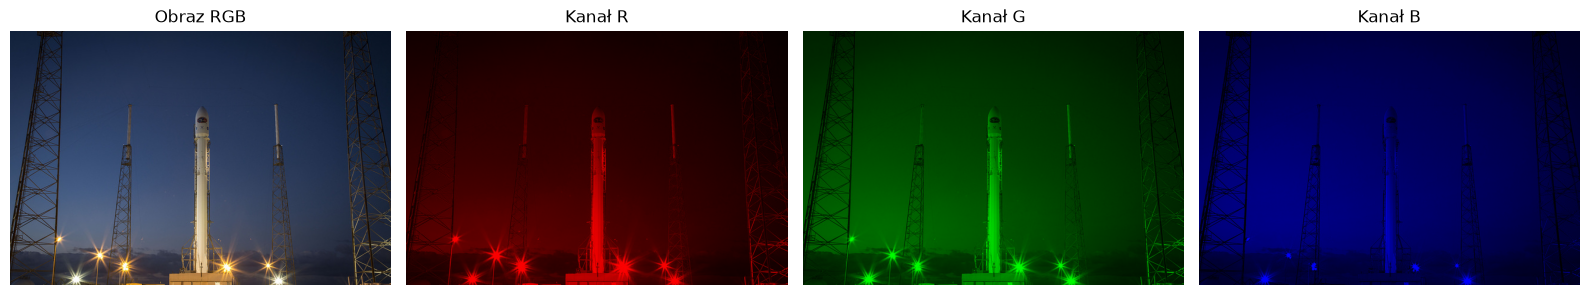

In [ ]:
# Jeśli obraz jest RGB, wyświetl jego kanały R, G i B

if len(img.shape) == 3:
    red = np.zeros_like(img)
    red[:, :, 0] = img[:, :, 0]

    green = np.zeros_like(img)
    green[:, :, 1] = img[:, :, 1]

    blue = np.zeros_like(img)
    blue[:, :, 2] = img[:, :, 2]

    # print(red)
    # print(green)
    # print(blue)

    # Wyświetlenie obrazu RGB oraz poszczególnych kanałów
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(img)
    axes[0].set_title("Obraz RGB")
    axes[0].axis("off")

    axes[1].imshow(red)
    axes[1].set_title("Kanał R")
    axes[1].axis("off")

    axes[2].imshow(green)
    axes[2].set_title("Kanał G")
    axes[2].axis("off")

    axes[3].imshow(blue)
    axes[3].set_title("Kanał B")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Obrazek nie jest RGB")

## 5. Przekonwertuj obraz do skali szarości

Jeżeli obraz jest kolorowy, przekonwertuj go do skali szarości:

```python
gray = color.rgb2gray(img)
```

Wyświetl obraz przed i po konwersji.

Ponownie sprawdź:

```python
gray.shape
gray.dtype
gray.min()
gray.max()
```

### Zastanów się

Co zmieniło się w strukturze danych po usunięciu informacji o kolorze?


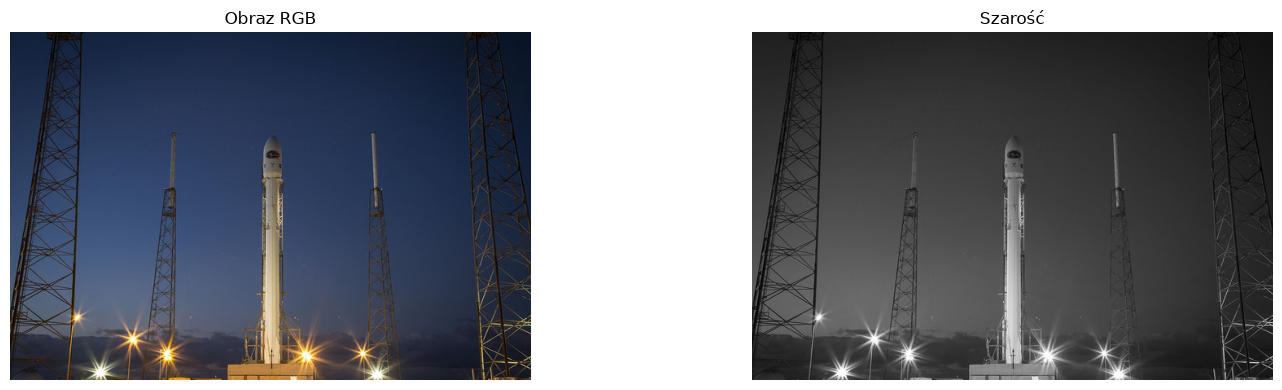

(427, 640)
float64
0.0
1.0


In [25]:
# Utwórz obraz w skali szarości
gray = color.rgb2gray(img)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

axes[0].imshow(img)
axes[0].set_title("Obraz RGB")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Szarość")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(gray.shape)
print(gray.dtype)
print(gray.min())
print(gray.max())

## 6. Narysuj histogram jasności

Dla obrazu w skali szarości utwórz histogram.

Użyj:

```python
bins=256
```

Pamiętaj, aby zakres histogramu odpowiadał zakresowi wartości pikseli.

Dla obrazu w zakresie `0–1`:

```python
range=(0, 1)
```

Dla obrazu w zakresie `0–255`:

```python
range=(0, 255)
```

Podpisz osie:

- oś X – poziom jasności,
- oś Y – liczba pikseli.

### Zastanów się

Czy większość pikseli znajduje się w obszarze ciemnych, średnich czy jasnych wartości?  
Czy histogram wykorzystuje szeroki zakres intensywności, czy wartości są skupione w niewielkim obszarze?


In [ ]:
# Narysuj histogram obrazu w skali szarości
bins = 256



## 7. Wykonaj normalizację

Wykonaj normalizację obrazu za pomocą:

```python
exposure.rescale_intensity()
```

Przeskaluj wartości pikseli do zakresu:

```text
0–1
```

Wyświetl:

**obraz przed normalizacją | obraz po normalizacji**

Narysuj również histogramy obu obrazów.

### Zastanów się

Czy zakres wartości został rozciągnięty?  
Czy kontrast obrazu zmienił się zauważalnie?  
Jeżeli zmiana jest niewielka, spróbuj wyjaśnić, z czego może to wynikać.


In [ ]:
# Wykonaj normalizację i porównaj obraz przed i po normalizacji



## 8. Wykonaj wyrównanie histogramu

Wykonaj wyrównanie histogramu:

```python
exposure.equalize_hist()
```

Wyświetl:

**obraz przed wyrównaniem | obraz po wyrównaniu**

Narysuj histogram obrazu wynikowego.

### Zastanów się

Jak zmienił się rozkład poziomów jasności?  
Czy szczegóły obrazu stały się bardziej widoczne?  
Czy histogram jest bardziej rozłożony w całym dostępnym zakresie?


In [ ]:
# Wykonaj wyrównanie histogramu i wyświetl wynik



## 9. Porównaj wyniki

Na jednej figurze wyświetl:

```text
Oryginał | Normalizacja | Wyrównanie histogramu
```

Poniżej umieść odpowiadające im histogramy.

Porównaj wygląd obrazów i rozkład intensywności.

### Zastanów się nad różnicą pomiędzy normalizacją i wyrównaniem histogramu

Normalizacja przede wszystkim rozciąga zakres wartości, natomiast wyrównanie histogramu zmienia sposób rozmieszczenia intensywności w tym zakresie.


In [ ]:
# Porównaj obraz oryginalny, po normalizacji i po wyrównaniu histogramu

